# BiLSTM with GloVe

Compare against `bilstm_baseline.ipynb` using the same data, architecture, and training settings.
Only the embedding initialization changes: Stanford GloVe 6B, 100 dimensions,
with fine-tuning enabled. Vocabulary is built from FPS training data only.

Run this notebook from the top in a separate kernel. The first run downloads the
shared official GloVe archive (about 862 MB) to `data/embeddings`; later runs reuse it.
This model needs fresh training. External games remain evaluation-only.


In [9]:
from contextlib import redirect_stdout
from io import StringIO

import torch
import matplotlib.pyplot as plt
from IPython.display import display
from torch import nn
import torch.nn.functional as F
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from sklearn.metrics import accuracy_score, f1_score

from text_data import create_dataloader, PAD_ID
from utils import get_device, plot_history
from train import train_model, evaluate
from glove_embeddings import ensure_glove_100d, initialize_glove_embedding

DATA_DIR = "data/merged"
GENRE = "FPS"
batch_size = 64

torch.manual_seed(42)

train_set, val_set, test_set, vocab = create_dataloader(
    DATA_DIR,
    genre=GENRE,
    batch_size=batch_size
)

In [10]:
class BiLSTM(nn.Module):
    def __init__(self, vocab_size, embed_size, num_hiddens, num_layers, dropout=0.5):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_size, padding_idx=PAD_ID)
        self.output_dropout = nn.Dropout(dropout)
        self.encoder = nn.LSTM(embed_size, num_hiddens, num_layers=num_layers, bidirectional=True)
        self.decoder = nn.Linear(4 * num_hiddens, 2)

    def forward(self, inputs, lengths):
        # inputs shape: (batch_size, time_step)
        # Transpose for LSTM's default time-first layout.
        # embeddings shape: (time_step, batch_size, embed_size)
        embeddings = self.embedding(inputs.T)

        # Skip padding during LSTM computation.
        packed = pack_padded_sequence(
            embeddings,
            lengths.cpu(),
            enforce_sorted=False,
        )

        packed_outputs, _ = self.encoder(packed)

        # outputs shape (time_step, batch_size, 2 * num_hiddens)
        outputs, _ = pad_packed_sequence(packed_outputs)

        # Pair each review index with its last valid token position.
        batch_indices = torch.arange(inputs.size(0), device=outputs.device)
        last_token_pos = lengths.to(outputs.device) - 1

        # All reviews start at 0, but their valid endings differ.
        first = outputs[0]
        last = outputs[last_token_pos, batch_indices]

        # Concatenate first and last valid outputs, each with both directions.
        # shape: (batch_size, 4 * num_hiddens)
        encoding = torch.cat((first, last), dim=1)
        outs = self.decoder(self.output_dropout(encoding))
        return outs


In [11]:
embed_size, num_hiddens, num_layers = 100, 100, 1
dropout = 0.5

net = BiLSTM(len(vocab), embed_size, num_hiddens, num_layers, dropout=dropout)


In [12]:
# Initialize only the existing training-vocabulary embedding rows.
# Keep this after model initialization and before optimizer creation.
freeze_embeddings = False
vectors_path = ensure_glove_100d()
glove_coverage = initialize_glove_embedding(
    net.embedding, vocab, vectors_path, freeze=freeze_embeddings,
)


GloVe coverage: 10214/11613 vocabulary words (88.0%)
Embedding trainable: True; unmatched words retain their random initialization.


Train loss: 0.048 | Train accuracy: 0.984 | Val accuracy: 0.807
Training on: cuda(NVIDIA GeForce RTX 5070 Ti)
Average speed: 93930 tokens/sec


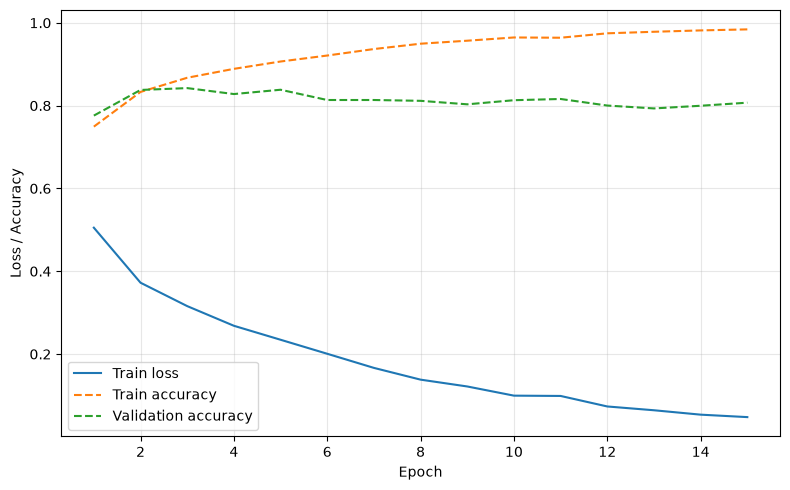

In [13]:
num_epochs, lr = 15, 1e-3
device = get_device()

# move model to device
net = net.to(device)

loss = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(net.parameters(), lr = lr)

training_output = StringIO()
status_display = display(
    {"text/plain": f"Training on: {device}\nStarting the first epoch..."},
    raw=True, display_id=True,
)

fig, ax = plt.subplots(figsize=(8, 5))
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss / Accuracy")
ax.set_title("Curves update after each completed epoch")
plot_display = display(fig, display_id=True)
plt.close(fig)


def update_plot(history):
    """Refresh the training curves after each epoch."""
    latest = history[-1]
    message = (
        f"Epoch {latest['epoch']:02d} | "
        f"Train loss: {latest['train']['loss']:.3f} | "
        f"Train accuracy: {latest['train']['accuracy']:.3f} | "
        f"Val accuracy: {latest['val']['accuracy']:.3f}\n"
    )
    status_display.update(
        {"text/plain": message + training_output.getvalue()}, raw=True
    )
    plot_history(history, ax=ax)
    ax.set_title("")
    plot_display.update(fig)


with redirect_stdout(training_output):
    metric_history = train_model(
        model=net,
        train_loader=train_set,
        val_loader=val_set,
        loss_fn=loss,
        optimizer=optimizer,
        num_epochs=num_epochs,
        device=device,
        on_epoch_end=update_plot,
    )

last_metrics = metric_history[-1]
final_results = (
    f"Train loss: {last_metrics['train']['loss']:.3f} | "
    f"Train accuracy: {last_metrics['train']['accuracy']:.3f} | "
    f"Val accuracy: {last_metrics['val']['accuracy']:.3f}\n"
)
status_display.update(
    {"text/plain": final_results + training_output.getvalue()}, raw=True
)

In [14]:
test_metrics = evaluate(
    model=net, 
    loader=test_set, 
    loss_fn=loss, 
    device=device)

print(f"Test loss:     {test_metrics['loss']:.4f}")
print(f"Test accuracy: {test_metrics['accuracy']:.4%}")
print(f"Test macro-F1: {test_metrics['macro_f1']:.4f}")

Test loss:     0.8520
Test accuracy: 83.0525%
Test macro-F1: 0.8269


## External tests

Run the cells below in this notebook's trained kernel. They evaluate all games in
`config.EXTERNAL_TEST_GAME_IDS` and the balanced 4,000-review IMDb movie test set.
Reuse the current trained model and its training-time text processing; no fitting
or vocabulary construction is performed here. IMDb uses sentiment labels
(0=negative, 1=positive), while Steam uses recommendation labels.


In [15]:
from pathlib import Path
import pandas as pd
import importlib
import config

# Refresh dataset configuration without restarting the trained kernel.
EXTERNAL_TEST_GAME_IDS = importlib.reload(config).EXTERNAL_TEST_GAME_IDS

external_test_dfs = {}
for game, appid in EXTERNAL_TEST_GAME_IDS.items():
    external_df = pd.read_csv(
        Path("data/processed") / f"reviews_{game}_{appid}.csv",
        usecols=["review", "voted_up"],
        dtype={"review": "string", "voted_up": "boolean"},
    )
    external_df = external_df.dropna(subset=["review", "voted_up"]).copy()
    external_df["voted_up"] = external_df["voted_up"].astype("int64")
    external_test_dfs[game] = external_df
    print(f"{game}: {len(external_df)} external test reviews")

# IMDb sentiment labels already use 0=negative and 1=positive.
imdb_test_df = pd.read_csv(
    Path("data/processed/reviews_IMDB_test.csv"),
    usecols=["review", "voted_up"],
    dtype={"review": "string", "voted_up": "int64"},
)
imdb_test_df = imdb_test_df.dropna(subset=["review", "voted_up"]).copy()
external_test_dfs["IMDB"] = imdb_test_df
print(f"IMDB: {len(imdb_test_df)} external test reviews")

from torch.utils.data import DataLoader
from text_data import ReviewDataset, collate_reviews

# Reuse the vocabulary and default length limit from training.
external_test_loaders = {
    game: DataLoader(
        ReviewDataset(external_df, vocab),
        batch_size=batch_size,
        shuffle=False,
        collate_fn=collate_reviews,
        num_workers=0,
    )
    for game, external_df in external_test_dfs.items()
}


WARDOGS: 1826 external test reviews
SQUAD: 1464 external test reviews
CYBERPUNK_2077: 1558 external test reviews
PERSONA_5_ROYAL: 1527 external test reviews
BALDURS_GATE_3: 1598 external test reviews
DOTA2: 967 external test reviews
HOLLOW_KNIGHT_SILKSONG: 1516 external test reviews
STARDEW_VALLEY: 1445 external test reviews
ELDEN_RING: 1476 external test reviews
FORZA_HORIZON_6: 1532 external test reviews
AMONG_US: 1301 external test reviews
IMDB: 4000 external test reviews


In [16]:
# evaluate() switches net to evaluation mode and disables gradients.
# It does not update weights or use the training optimizer.
external_results = []
for game, external_loader in external_test_loaders.items():
    external_metrics = evaluate(
        model=net,
        loader=external_loader,
        loss_fn=loss,
        device=device,
    )
    external_results.append({
        "game": game,
        "samples": len(external_loader.dataset),
        "loss": external_metrics["loss"],
        "accuracy": external_metrics["accuracy"],
        "macro_f1": external_metrics["macro_f1"],
    })
    print(
        f"{game}: loss={external_metrics['loss']:.4f} | "
        f"accuracy={external_metrics['accuracy']:.4%} | "
        f"macro-F1={external_metrics['macro_f1']:.4f}"
    )

external_results = pd.DataFrame(external_results).set_index("game")
print("\nExternal test summary:")
print(external_results.to_string(float_format=lambda value: f"{value:.4f}"))


WARDOGS: loss=1.2695 | accuracy=78.0942% | macro-F1=0.7757
SQUAD: loss=0.8579 | accuracy=83.3333% | macro-F1=0.8268
CYBERPUNK_2077: loss=0.9847 | accuracy=82.0924% | macro-F1=0.8122
PERSONA_5_ROYAL: loss=0.9566 | accuracy=79.0439% | macro-F1=0.7853
BALDURS_GATE_3: loss=1.0010 | accuracy=81.2891% | macro-F1=0.8106
DOTA2: loss=1.0479 | accuracy=77.8697% | macro-F1=0.7707
HOLLOW_KNIGHT_SILKSONG: loss=1.0880 | accuracy=78.1003% | macro-F1=0.7759
STARDEW_VALLEY: loss=0.9784 | accuracy=79.1003% | macro-F1=0.7907
ELDEN_RING: loss=0.9427 | accuracy=79.8103% | macro-F1=0.7940
FORZA_HORIZON_6: loss=1.2072 | accuracy=80.2219% | macro-F1=0.7835
AMONG_US: loss=0.9769 | accuracy=80.0922% | macro-F1=0.7917
IMDB: loss=1.6449 | accuracy=68.1250% | macro-F1=0.6731

External test summary:
                        samples   loss  accuracy  macro_f1
game                                                      
WARDOGS                    1826 1.2695    0.7809    0.7757
SQUAD                      1464 0.8579    